# 00 · FaceCloud AI: models, how the pipeline uses them, and the scorecard

This notebook covers three things:

1. **Which models does the system run, and what is each for?**
2. **Does the application really use them, and where do the per-image scores come from?** (read from the database, not typed in)
3. **How good is each one?** (the scorecard collects the numbers measured in notebooks 01-10)

> **About the models.** None of the neural models running in the application was fine-tuned: they are public pretrained models (one small fine-tuning *experiment* on Zero-DCE is documented in notebook 11 and was not installed), **selected, evaluated and integrated** for this use case. What the project engineered is the *adaptive pipeline around them*: the router that picks an operation per defect, the validator gates (SSIM, structure, identity, geometry) that accept or refuse every result, the identity safety checks, and the thresholds calibrated on the project's own photographs. Notebooks 01-10 measure the models exactly as the application runs them, on public stock photographs, with ground truth where it can be constructed.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


## 1 · Model inventory (files on the server, switches in the configuration)

In [2]:
import hashlib
models_dir = ROOT / ".runtime" / "models"
inventory = [
 ("YuNet", "face detection", "yunet_s_dynamic.onnx", "MIT", "always on", "01"),
 ("SFace", "face identity embedding", "face_recognition_sface_2021dec.onnx", "Apache-2.0", "always on", "02"),
 ("Zero-DCE", "low-light enhancement", "zero_dce_epoch99.onnx", "research (public weights)", str(settings.ZERO_DCE_ENABLED), "03"),
 ("NAFNet GoPro", "motion deblur", "NAFNet-GoPro-width64.pth", "MIT", str(settings.NAFNET_DEBLUR_ENABLED), "04"),
 ("NAFNet SIDD", "denoise", "NAFNet-SIDD-width64.pth", "MIT", str(settings.NAFNET_DENOISE_ENABLED) + " (tested, off)", "05"),
 ("Real-ESRGAN compact", "upscale / detail (default)", "realesr-general-x4v3.pth", "BSD-3-Clause", str(settings.HD_RESTORATION_ENABLED), "06"),
 ("Real-ESRGAN x4plus", "upscale (slow fallback)", "RealESRGAN_x4plus.pth", "BSD-3-Clause", str(settings.HD_RESTORATION_ENABLED), "06"),
 ("CodeFormer", "face restoration", "codeformer/codeformer.pth", "S-Lab (non-commercial)", str(settings.CODEFORMER_ENABLED), "07"),
 ("DDColor", "colorization", "ddcolor/ddcolor_paper.bin", "Apache-2.0", str(settings.DDCOLOR_ENABLED), "08"),
 ("SigLIP ViT-B/16", "semantic photo search", "siglip-vit-b-16/open_clip_model.safetensors", "Apache-2.0", str(settings.SEMANTIC_SEARCH_ENABLED), "09"),
 ("GFPGAN v1.4", "face restoration (alternative)", "gfpgan/GFPGANv1.4.pth", "Apache-2.0", str(settings.GFPGAN_ENABLED) + " (never used)", "-"),
]
rows = []
for name, task, filename, licence, enabled, nb in inventory:
    path = models_dir / filename
    rows.append({"model": name, "task": task, "file_MB": round(path.stat().st_size / 1e6, 1) if path.exists() else "missing", "licence": licence, "enabled": enabled, "weights": "pretrained (public)", "notebook": nb})
table(rows)

model                task                            file_MB  licence                    enabled              weights              notebook
-------------------  ------------------------------  -------  -------------------------  -------------------  -------------------  --------
YuNet                face detection                  0.2      MIT                        always on            pretrained (public)  01      
SFace                face identity embedding         38.7     Apache-2.0                 always on            pretrained (public)  02      
Zero-DCE             low-light enhancement           0.3      research (public weights)  True                 pretrained (public)  03      
NAFNet GoPro         motion deblur                   271.8    MIT                        True                 pretrained (public)  04      
NAFNet SIDD          denoise                         464.2    MIT                        False (tested, off)  pretrained (public)  05      
Real-ESRGAN compact 

## 2 · Proof that the pipeline uses them: engines run and accepted in the stored results

282 completed enhancement results
operation              engine                   ran  stage_accepted  accept_rate
---------------------  -----------------------  ---  --------------  -----------
detail_restoration     general                  147  105             71%        
super_resolution       realesrgan               80   56              70%        
low_light_enhancement  zero_dce                 75   59              79%        
motion_deblurring      nafnet_gopro             65   23              35%        
polish                 opencv_polish            47   40              85%        
cloud_enhancement      deep_image_auto_enhance  41   41              100%       
face_restoration       codeformer               37   17              46%        
low_light_enhancement  opencv_exposure          26   15              58%        
denoising              opencv_nlm               14   12              86%        
detail_restoration     ultrasharp               11   2               18%   

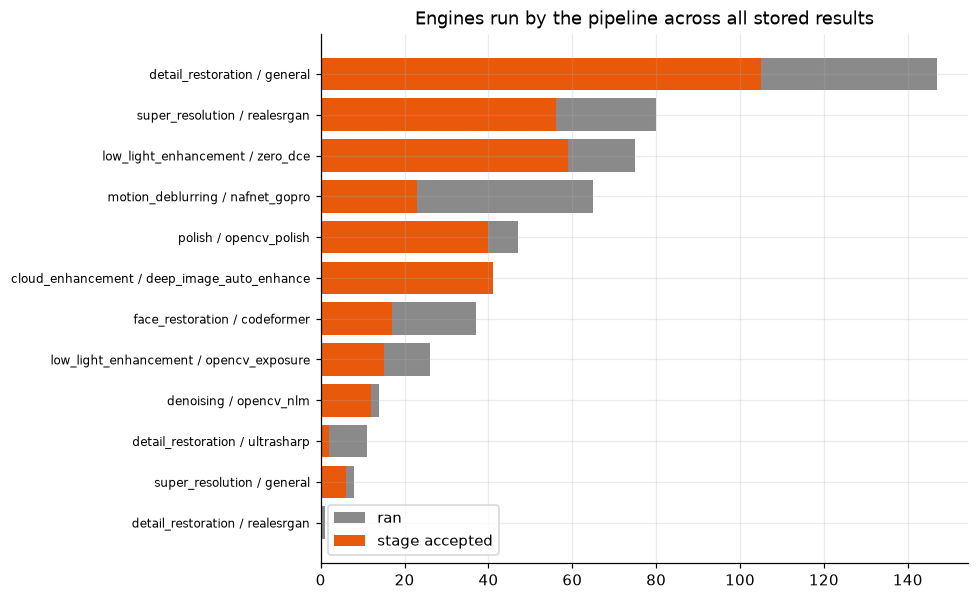

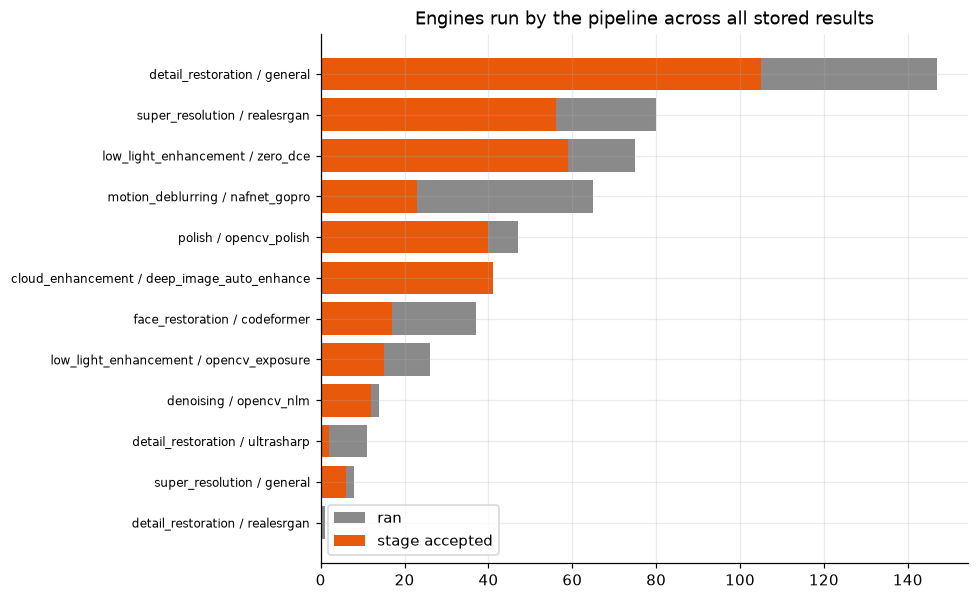

In [3]:
from collections import Counter
from enhancement.models import ImageEnhancementResult
results = list(ImageEnhancementResult.objects.filter(status="completed"))
run, accepted = Counter(), Counter()
for r in results:
    for stage in (r.applied_parameters.get("adaptive") or {}).get("stages") or []:
        for engine in stage.get("models_run") or []:
            run[(stage["operation"], engine)] += 1
            if stage.get("status") == "accepted": accepted[(stage["operation"], engine)] += 1
keys = sorted(run, key=lambda k: -run[k])
print(f"{len(results)} completed enhancement results")
table([{"operation": op, "engine": eng, "ran": run[(op, eng)], "stage_accepted": accepted[(op, eng)], "accept_rate": f"{accepted[(op, eng)] / run[(op, eng)]:.0%}"} for op, eng in keys])
fig, ax = plt.subplots(figsize=(9, 0.38 * len(keys) + 1)); y = np.arange(len(keys))
ax.barh(y, [run[k] for k in keys], color=COLORS["input"], label="ran"); ax.barh(y, [accepted[k] for k in keys], color=COLORS["model"], label="stage accepted")
ax.set_yticks(y, [f"{op} / {eng}" for op, eng in keys], fontsize=8); ax.invert_yaxis(); ax.set_title("Engines run by the pipeline across all stored results"); ax.legend(); fig.tight_layout(); save(fig, "00_engine_usage.png")

## 3 · Where the per-image scores come from (one stored result, traced end to end)

In [4]:
import json
from enhancement.models import ImageEnhancementResult as R
demo = None
for only_public in (True, False):
    qs = R.objects.filter(status="completed").order_by("-id")
    if only_public: qs = qs.filter(image__original_name__icontains="unsplash")
    for r in qs:
        p = r.applied_parameters; stages = (p.get("adaptive") or {}).get("stages") or []
        if len(stages) >= 2 and p.get("quality_before") and p.get("quality_after"): demo = r; break
    if demo: break
p = demo.applied_parameters; before, after = p["quality_before"], p["quality_after"]
print(f"image #{demo.image_id} ({demo.image.original_name[:30]}), preset {p.get('requested_level')}/{p.get('style')}, {demo.processing_duration_ms / 1000:.1f}s total\n")
print("quality_before ->", {k: before[k] for k in ("mean_luminance", "contrast_stddev", "laplacian_sharpness", "estimated_noise")}, "edge_sharpness", before["blur"]["edge_sharpness"])
for s in p["adaptive"]["stages"]:
    print(f"  stage {s['operation']:24s} models_run={s.get('models_run')} status={s.get('status')} chosen={s.get('chosen')} {s.get('seconds', 0):.1f}s")
print("quality_after  ->", {k: after[k] for k in ("mean_luminance", "contrast_stddev", "laplacian_sharpness", "estimated_noise")}, "edge_sharpness", after["blur"]["edge_sharpness"])
print("identity_verification ->", {k: (p.get("identity_verification") or {}).get(k) for k in ("similarity", "threshold", "status")}, "| quality_gate ->", p.get("quality_gate"))

image #373 (mohammad-esmaeili-T_qW4JkdabU-), preset high/ai_max, 156.8s total

quality_before -> {'mean_luminance': 95.1, 'contrast_stddev': 40.0, 'laplacian_sharpness': 74.94, 'estimated_noise': 1.0} edge_sharpness 0.3835
  stage face_restoration         models_run=[] status=unavailable chosen=None 0.0s
  stage polish                   models_run=['opencv_polish'] status=accepted chosen=c1_polish 23.9s
quality_after  -> {'mean_luminance': 95.0, 'contrast_stddev': 41.36, 'laplacian_sharpness': 120.57, 'estimated_noise': 1.0} edge_sharpness 0.3683
identity_verification -> {'similarity': 0.8036, 'threshold': 0.8, 'status': 'verified'} | quality_gate -> {'decision': 'accepted', 'bypassed': False}


processing time: median 17.0s, 90th percentile 67.9s


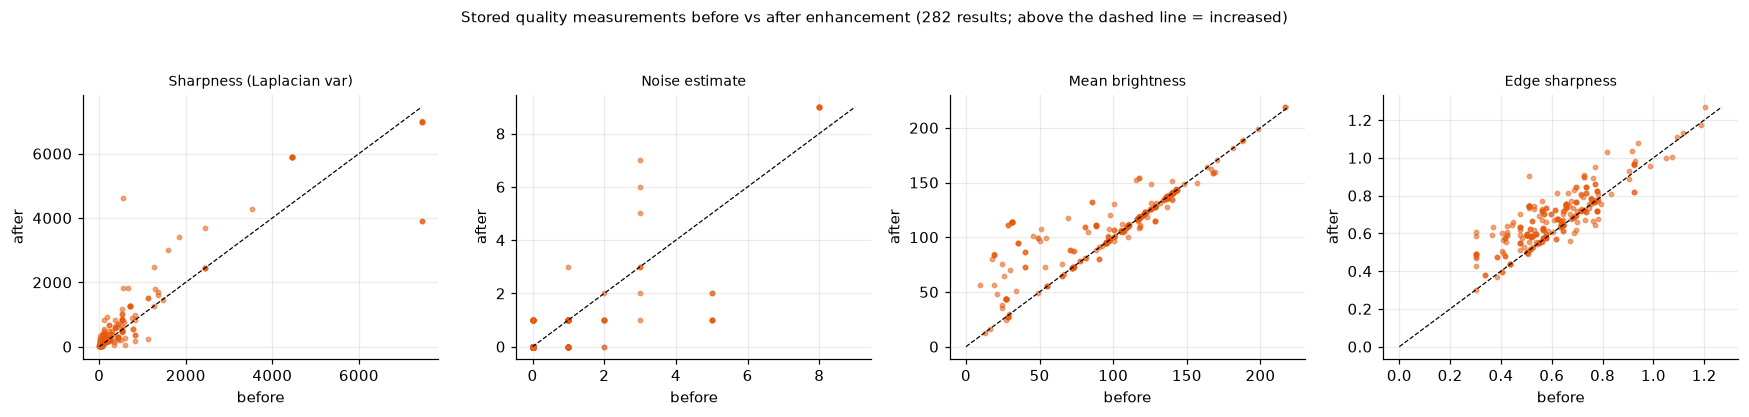

In [5]:
b = [(r.applied_parameters.get("quality_before") or {}, r.applied_parameters.get("quality_after") or {}) for r in results if r.applied_parameters.get("quality_before") and r.applied_parameters.get("quality_after")]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for axis, (key, title) in zip(ax, (("laplacian_sharpness", "Sharpness (Laplacian var)"), ("estimated_noise", "Noise estimate"), ("mean_luminance", "Mean brightness"), ("edge", "Edge sharpness"))):
    def getv(q, key=key):
        try: return float(q["blur"]["edge_sharpness"] if key == "edge" else q[key])
        except (KeyError, TypeError): return np.nan
    xs = np.array([getv(q0) for q0, q1 in b], float); ys = np.array([getv(q1) for q0, q1 in b], float); ok = np.isfinite(xs) & np.isfinite(ys); xs, ys = xs[ok], ys[ok]
    axis.scatter(xs, ys, s=8, alpha=0.5, color=COLORS["model"]); lim = [0, max(xs.max(), ys.max())]; axis.plot(lim, lim, "k--", lw=0.8); axis.set_xlabel("before"); axis.set_ylabel("after"); axis.set_title(title, fontsize=9)
fig.suptitle(f"Stored quality measurements before vs after enhancement ({len(b)} results; above the dashed line = increased)", y=1.04, fontsize=10); fig.tight_layout(); save(fig, "00_before_after_scores.png")
seconds = np.array([r.processing_duration_ms / 1000 for r in results]); print("processing time: median %.1fs, 90th percentile %.1fs" % (np.median(seconds), np.percentile(seconds, 90)))

## 4 · The scorecard (numbers measured in notebooks 01-10)

In [6]:
card = json.loads((OUT / "scorecard.json").read_text())
for model, entry in card.items():
    print(f"\n== {model}  [{entry['task']}]  {entry['note']}")
    for k, v in entry["metrics"].items(): print(f"   {k:38s} {v}")


== Zero-DCE  [low-light enhancement]  no ground truth: brightness gain, noise amplification, SSIM to input
   images                                 8
   mean_brightness_gain_x                 2.9963
   gamma_baseline_gain_x                  2.1332
   noise_amplification_x                  2.6275
   mean_ssim_vs_input                     0.5249
   mean_seconds                           0.1987

== NAFNet GoPro  [motion deblur]  synthetic motion blur with ground truth, 6 public photos
   images                                 6
   psnr_blurred_db                        27.0633
   ssim_blurred                           0.8108
   mae_blurred                            6.1159
   psnr_unsharp_db                        27.1083
   ssim_unsharp                           0.8128
   mae_unsharp                            6.1309
   psnr_nafnet_db                         30.9283
   ssim_nafnet                            0.8982
   mae_nafnet                             4.0572
   mean_seconds        

## 5 · Summary
* **Models:** 11 pretrained models in use (plus an optional cloud API for the Pro preset). each was selected, benchmarked here and integrated. A small Zero-DCE fine-tuning experiment (notebook 11) did not beat the official weights and was left out.
* **Our contribution:** the adaptive router (which operation for which defect), the validator gates, the identity safety layer, the quality-control thresholds, the person-folder grouping, and the evidence that each step is judged before it is shown to the user.
* **Evaluation metrics used:** PSNR, SSIM, MAE (against ground truth), sharpness ratio, noise estimate, colorfulness and Lab chroma error, ROC-AUC / EER / true-and-false match rate (identity), recall under degradation (detection), average precision / precision@k (search), processing time.
* **Evaluated and removed:** 4x-UltraSharp (ran 11 times in the stored results, accepted twice, non-commercial licence) and Retinexformer (never beat Zero-DCE) were deleted from the server.
* **Known limits (measured above):** Real-ESRGAN scores lower than bicubic on PSNR/SSIM (it adds texture), NAFNet-SIDD is not better than non-local means on heavy Gaussian noise, DDColor is conservative, proxy labels were used for search.